## Regularization and Generalization

### Learning Goals
* Understand why complex, unconstrained models overfit noise in training data.
* Contrast Ridge ($L_2$) and Lasso ($L_1$) regularization penalty functions.
* Analyze the **bias-variance trade-off** and evaluate the necessity of feature standardization.

---

### 1. Penalizing Model Complexity

High-capacity models can fit training points perfectly while failing to generalize to unseen test observations. **Regularization** mitigates overfitting by appending a parameter complexity penalty to the loss objective:

* **Ridge Regression ($L_2$ Penalty):**
  $$
  L(\beta) = \text{MSE} + \lambda \sum_{j} \beta_j^2
  $$
  Shrinks coefficient magnitudes smoothly toward zero.

* **Lasso Regression ($L_1$ Penalty):**
  $$
  L(\beta) = \text{MSE} + \lambda \sum_{j} |\beta_j|
  $$
  Drives uninformative coefficients strictly to zero, performing automatic feature selection.

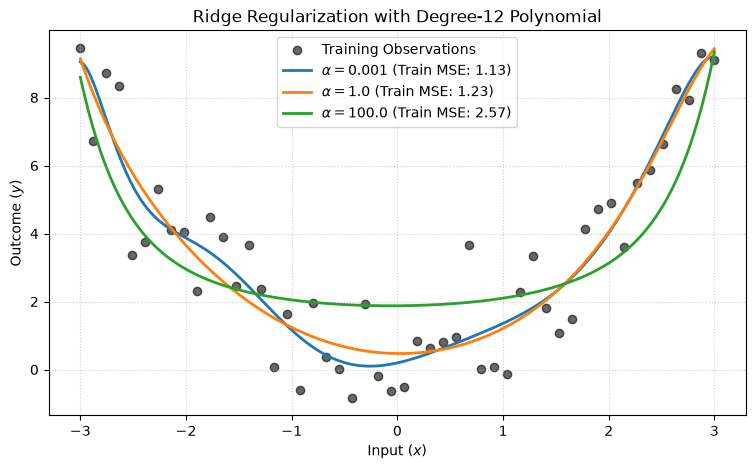

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(42)

x = np.linspace(-3, 3, 50).reshape(-1, 1)
y = x[:, 0]**2 + rng.normal(0, 1.5, len(x))

x_grid = np.linspace(-3, 3, 300).reshape(-1, 1)

plt.figure(figsize=(9, 5))
plt.scatter(x[:, 0], y, color='black', alpha=0.6, label="Training Observations")

for alpha in [0.001, 1.0, 100.0]:
    model = make_pipeline(
        PolynomialFeatures(degree=12, include_bias=False),
        StandardScaler(),
        Ridge(alpha=alpha),
    )
    model.fit(x, y)
    prediction = model.predict(x_grid)
    
    train_pred = model.predict(x)
    mse = mean_squared_error(y, train_pred)
    
    # Using 'rf' here prevents \alpha from turning into a bell character
    plt.plot(x_grid[:, 0], prediction, linewidth=2, label=rf"$\alpha = {alpha}$ (Train MSE: {mse:.2f})")

plt.xlabel("Input ($x$)")
plt.ylabel("Outcome ($y$)")
plt.title("Ridge Regularization with Degree-12 Polynomial")
plt.legend()
plt.grid(linestyle=':', alpha=0.6)
plt.show()

### 2. The Bias-Variance Trade-Off and Feature Standardization

> **Core Insight:** Increasing regularization strength ($\lambda$ or $\alpha$) reduces variance (preventing wild oscillations) at the expense of higher bias (underfitting if penalty is too extreme).
>
> **Feature Scaling Requirement:** Regularization penalties sum over parameter magnitudes. Without `StandardScaler`, features with larger numerical scales face disproportionate penalization regardless of their true predictive power.

---

### Exercises

Try each problem before running the verification code below:

1. Compare the regression curves across the three $\alpha$ values in the plot above.
2. Why is training set error an invalid metric for selecting hyperparameter $\alpha$?
3. Explain the fundamental operational difference between Ridge ($L_2$) and Lasso ($L_1$) penalties.

In [2]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

print("\n1. Curve Comparison:")
print("   - alpha = 0.001: Fits noise aggressively (high variance, wiggly curve).")
print("   - alpha = 1.0:   Smooth quadratic curve capturing underlying pattern (optimal balance).")
print("   - alpha = 100.0: Oversimplified, near-flat line (high bias, severe underfitting).")

print("\n2. Why Training Error Cannot Select Alpha:")
print("   - Training error monotonically increases with stronger regularization (alpha = 0.001 yields lowest train MSE),")
print("     obscuring generalization failure. Hyperparameters must be tuned via cross-validation.")

print("\n3. Ridge vs. Lasso Difference:")
print("   - Ridge (L2) shrinks parameters continuously toward zero without making them exactly zero.")
print("   - Lasso (L1) uses a sharp penalty diamond that sets uninformative parameters strictly to zero.")

=== Exercise Solutions & Checks ===

1. Curve Comparison:
   - alpha = 0.001: Fits noise aggressively (high variance, wiggly curve).
   - alpha = 1.0:   Smooth quadratic curve capturing underlying pattern (optimal balance).
   - alpha = 100.0: Oversimplified, near-flat line (high bias, severe underfitting).

2. Why Training Error Cannot Select Alpha:
   - Training error monotonically increases with stronger regularization (alpha = 0.001 yields lowest train MSE),
     obscuring generalization failure. Hyperparameters must be tuned via cross-validation.

3. Ridge vs. Lasso Difference:
   - Ridge (L2) shrinks parameters continuously toward zero without making them exactly zero.
   - Lasso (L1) uses a sharp penalty diamond that sets uninformative parameters strictly to zero.
